实现计算图的数据存储和自动反向传播 

In [148]:
import math
class Value:
    def __init__(self,data,_children=(),_operation='',label=''):
        self.data=data
        self._pre=set(_children)
        self._operation=_operation
        self.label=label
        self._backward=lambda:None # 空函数
        self.grad=0
    # 打印
    def __repr__(self):
        return f"Value(data={self.data})"
    # 运算    
    def __add__(self, other):
        # if other is not Value class 可以把他变成Value类
        other = other if isinstance(other, Value) else Value(other)
        out=Value(self.data+other.data,(self,other),"+")
        def _backward():
            self.grad+=1.0*out.grad
            other.grad+=1.0*out.grad
        out._backward=_backward
        return out
    def __sub__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return Value(self.data - other.data, (self, other), "-")
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out=Value(self.data*other.data,(self,other),"*")
        def _backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad
        out._backward=_backward
        return out
    def __truediv__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return self*other**(-1)
    def __pow__(self,other):
        assert isinstance(other,(int,float)),"仅支持整数或者浮点数作为指数"
        out=Value(self.data**other,(self,),"pow")
        def _backward():
            self.grad+=out.grad*other*(self.data**(other-1))
            # other.grad=out.grad*()
        out._backward=_backward
        return out
    def __rsub__(self, other):
        return Value(other - self.data, (self,), "-")
    def __radd__(self, other):
        return self.__add__(Value(other))
    def __rmul__(self, other):
        return self.__mul__(Value(other))
    
    # 反向传播
    def backward(self):
        # 拓扑排序
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._pre:
                    build_topo(child)
                topo.append(v)
        build_topo(self)   
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

    # 激活函数
    def tanh(self):
        x=self.data
        t=(math.exp(x) - math.exp(-x)) / (math.exp(x) + math.exp(-x))
        out=Value(t,(self,),"tanh")
        def _backward():
            self.grad+=(1-t**2)*out.grad
        out._backward=_backward
        return out


In [149]:
from graphviz import Digraph
def trace(root):
    nodes,edges=set(),set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._pre:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes,edges

def draw_dot(root):
    dot=Digraph(format='svg',graph_attr={'rankdir':"LR"})
    nodes,edges=trace(root)
    for n in nodes:
        uid=str(id(n))
        dot.node(name=uid, label="{ %s | data=%.4f | grad=%.4f }" % (n.label,n.data,n.grad), shape='record')
        if n._operation:
        # 创建操作节点并连线
            dot.node(name=uid + n._operation, label=n._operation)
            dot.edge(uid + n._operation, uid)
    for n1, n2 in edges:
    # 标注 2 所在位置：连接 n1 到 n2 的操作节点
        dot.edge(str(id(n1)), str(id(n2)) + n2._operation)
    return dot


In [150]:
a=Value(5,label='a')
b=Value(10,label='b')
c=a+b
c.label='c'
d=Value(0.1)*c
d.label='d'

e=d.tanh()
e.label='e'

e.backward()

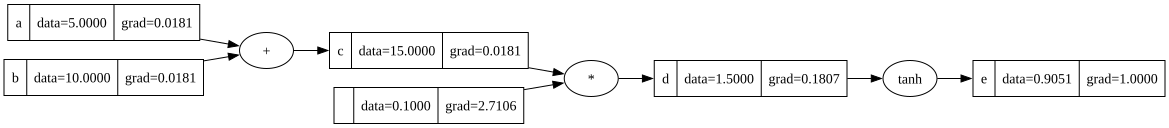

In [151]:
draw_dot(e)

梯度叠加的问题，有多个相同变量参与计算

e=(a+b)*(a+c)

In [152]:
a=Value(5,label='a')
b=Value(10,label='b')
c=Value(3,label='c')
e=(a+b)*(c+a)
e.label='e'
e.backward()

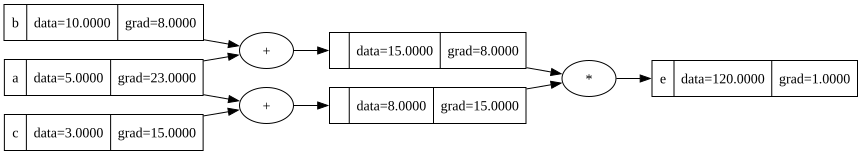

In [153]:
draw_dot(e)